In [1]:
from pathlib import Path
from zipfile import ZipFile

from google.colab import drive
drive.mount("/content/drive")

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"

if not project_dir.exists():
    raise FileNotFoundError(f"Groundnut folder not found: {project_dir}")

zip_files = sorted(project_dir.glob("*.zip"))

print("ZIP files found:")
for path in zip_files:
    print(f"  {path.name} ({path.stat().st_size / (1024**3):.2f} GB)")

if not zip_files:
    raise FileNotFoundError(f"No ZIP files found directly inside {project_dir}")

if len(zip_files) > 1:
    raise RuntimeError("More than one ZIP found. Paste the list so we can select the correct archive.")

archive = zip_files[0]
dataset_dir.mkdir(parents=True, exist_ok=True)

# Check every archive path stays inside dataset_dir before extracting.
destination = dataset_dir.resolve()
with ZipFile(archive) as zf:
    for member in zf.infolist():
        target = (dataset_dir / member.filename).resolve()
        if target != destination and destination not in target.parents:
            raise ValueError(f"Unsafe path in ZIP; extraction stopped: {member.filename}")

    zf.extractall(dataset_dir)

print(f"\nExtracted: {archive.name}")
print(f"Dataset folder: {dataset_dir}")

print("\nTop-level contents:")
for item in sorted(dataset_dir.iterdir()):
    marker = "[DIR]" if item.is_dir() else "[FILE]"
    print(f"  {marker} {item.name}")

Mounted at /content/drive
ZIP files found:
  Raw_Data.zip (0.75 GB)

Extracted: Raw_Data.zip
Dataset folder: /content/drive/MyDrive/final_year_project/groundnut/dataset

Top-level contents:
  [DIR] Raw_Data


In [3]:
from pathlib import Path
from collections import Counter
from PIL import Image, UnidentifiedImageError
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
image_paths = sorted(
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

print(f"Images found: {len(image_paths):,}")

rows = []
size_counts = Counter()
unreadable = []

for i, path in enumerate(image_paths, start=1):
    try:
        with Image.open(path) as image:
            image.verify()

        # Reopen after verify to read dimensions.
        with Image.open(path) as image:
            width, height = image.size
            image_format = image.format

        size_counts[(width, height)] += 1
        rows.append({
            "relative_path": str(path.relative_to(dataset_dir)),
            "folder": path.parent.name,
            "width": width,
            "height": height,
            "format": image_format,
            "readable": True,
        })
    except (UnidentifiedImageError, OSError, ValueError) as error:
        unreadable.append((path, str(error)))
        rows.append({
            "relative_path": str(path.relative_to(dataset_dir)),
            "folder": path.parent.name,
            "width": None,
            "height": None,
            "format": None,
            "readable": False,
        })

    if i % 250 == 0 or i == len(image_paths):
        print(f"Checked {i:,}/{len(image_paths):,} images")

report_path = project_dir / "inventory_report.csv"
report_df = pd.DataFrame(rows)
report_df.to_csv(report_path, index=False)

print("\nCounts by containing folder:")
if rows:
    folder_counts = report_df.groupby("folder").size().sort_values(ascending=False)
    for folder, count in folder_counts.items():
        print(f"  {folder}: {count:,}")
else:
    print("  No image files found.")

print(f"\nReadable: {len(image_paths) - len(unreadable):,}")
print(f"Unreadable: {len(unreadable):,}")

if unreadable:
    print("\nUnreadable files:")
    for path, error in unreadable[:30]:
        print(f"  {path.relative_to(dataset_dir)} — {error}")
    if len(unreadable) > 30:
        print(f"  ... and {len(unreadable) - 30:,} more")

print("\nMost common image sizes (width × height):")
for (width, height), count in size_counts.most_common(20):
    print(f"  {width} × {height}: {count:,}")

print(f"\nDetailed inventory saved to: {report_path}")

Images found: 3,058
Checked 250/3,058 images
Checked 500/3,058 images
Checked 750/3,058 images
Checked 1,000/3,058 images
Checked 1,250/3,058 images
Checked 1,500/3,058 images
Checked 1,750/3,058 images
Checked 2,000/3,058 images
Checked 2,250/3,058 images
Checked 2,500/3,058 images
Checked 2,750/3,058 images
Checked 3,000/3,058 images
Checked 3,058/3,058 images

Counts by containing folder:
  healthy leaf: 929
  early_leaf_spot: 885
  late leaf spot: 689
  nutrition deficiency: 329
  rust: 226

Readable: 3,058
Unreadable: 0

Most common image sizes (width × height):
  1200 × 800: 3,058

Detailed inventory saved to: /content/drive/MyDrive/final_year_project/groundnut/inventory_report.csv


In [4]:
from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

image_paths = sorted(
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

hash_groups = defaultdict(list)

for i, path in enumerate(image_paths, start=1):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    hash_groups[digest.hexdigest()].append(path)

    if i % 250 == 0 or i == len(image_paths):
        print(f"Hashed {i:,}/{len(image_paths):,} images")

duplicate_groups = [
    (digest, paths)
    for digest, paths in hash_groups.items()
    if len(paths) > 1
]

rows = []
conflict_rows = []

for group_number, (digest, paths) in enumerate(duplicate_groups, start=1):
    labels = sorted({path.parent.name for path in paths})
    is_conflict = len(labels) > 1

    for path in paths:
        row = {
            "group_id": group_number,
            "sha256": digest,
            "relative_path": str(path.relative_to(dataset_dir)),
            "label_folder": path.parent.name,
            "group_size": len(paths),
            "conflicting_labels": is_conflict,
        }
        rows.append(row)
        if is_conflict:
            conflict_rows.append(row)

duplicates_path = project_dir / "exact_duplicate_manifest.csv"
conflicts_path = project_dir / "conflicting_label_duplicates.csv"

pd.DataFrame(rows).to_csv(duplicates_path, index=False)
pd.DataFrame(conflict_rows).to_csv(conflicts_path, index=False)

duplicate_file_count = sum(len(paths) for _, paths in duplicate_groups)
conflict_group_count = sum(
    len({path.parent.name for path in paths}) > 1
    for _, paths in duplicate_groups
)

print(f"\nImages hashed: {len(image_paths):,}")
print(f"Exact duplicate groups: {len(duplicate_groups):,}")
print(f"Files belonging to duplicate groups: {duplicate_file_count:,}")
print(f"Conflicting-label duplicate groups: {conflict_group_count:,}")
print(f"\nDuplicate manifest: {duplicates_path}")
print(f"Conflict report: {conflicts_path}")

if conflict_rows:
    print("\nConflicting-label duplicate groups:")
    conflict_df = pd.DataFrame(conflict_rows)
    for group_id, group in conflict_df.groupby("group_id"):
        labels = sorted(group["label_folder"].unique())
        print(f"\nGroup {group_id}: labels={labels}")
        for relative_path in group["relative_path"]:
            print(f"  {relative_path}")


Hashed 250/3,058 images
Hashed 500/3,058 images
Hashed 750/3,058 images
Hashed 1,000/3,058 images
Hashed 1,250/3,058 images
Hashed 1,500/3,058 images
Hashed 1,750/3,058 images
Hashed 2,000/3,058 images
Hashed 2,250/3,058 images
Hashed 2,500/3,058 images
Hashed 2,750/3,058 images
Hashed 3,000/3,058 images
Hashed 3,058/3,058 images

Images hashed: 3,058
Exact duplicate groups: 0
Files belonging to duplicate groups: 0
Conflicting-label duplicate groups: 0

Duplicate manifest: /content/drive/MyDrive/final_year_project/groundnut/exact_duplicate_manifest.csv
Conflict report: /content/drive/MyDrive/final_year_project/groundnut/conflicting_label_duplicates.csv


In [5]:
!pip -q install ImageHash

from pathlib import Path
from itertools import combinations
from PIL import Image, ImageOps, ImageDraw
import imagehash
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
threshold = 8
preview_limit = 60

image_paths = sorted(
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

hash_records = []
unreadable = []

for i, path in enumerate(image_paths, start=1):
    try:
        with Image.open(path) as image:
            phash = imagehash.phash(image.convert("RGB"))
        hash_records.append((path, phash))
    except Exception as error:
        unreadable.append((path, str(error)))

    if i % 250 == 0 or i == len(image_paths):
        print(f"Hashed {i:,}/{len(image_paths):,} images")

pairs = []
for (path_a, hash_a), (path_b, hash_b) in combinations(hash_records, 2):
    distance = hash_a - hash_b
    if distance <= threshold:
        pairs.append({
            "path_a": str(path_a.relative_to(dataset_dir)),
            "label_a": path_a.parent.name,
            "path_b": str(path_b.relative_to(dataset_dir)),
            "label_b": path_b.parent.name,
            "phash_distance": distance,
            "cross_label": path_a.parent.name != path_b.parent.name,
        })

pairs.sort(key=lambda row: (row["phash_distance"], row["path_a"], row["path_b"]))

pairs_path = project_dir / "near_duplicate_candidates.csv"
pd.DataFrame(pairs).to_csv(pairs_path, index=False)

print(f"\nImages hashed: {len(hash_records):,}")
print(f"Unreadable/skipped: {len(unreadable):,}")
print(f"Candidate pairs (pHash distance ≤ {threshold}): {len(pairs):,}")
print(f"Cross-label candidate pairs: {sum(row['cross_label'] for row in pairs):,}")
print(f"Pair list: {pairs_path}")

if pairs:
    shown_pairs = pairs[:preview_limit]
    cell_w, cell_h, label_h = 220, 220, 48
    sheet = Image.new(
        "RGB",
        (cell_w * 2, (cell_h + label_h) * len(shown_pairs)),
        "white",
    )
    draw = ImageDraw.Draw(sheet)

    for index, row in enumerate(shown_pairs):
        y = index * (cell_h + label_h)
        path_a = dataset_dir / row["path_a"]
        path_b = dataset_dir / row["path_b"]

        for col, path in enumerate((path_a, path_b)):
            with Image.open(path) as image:
                thumb = ImageOps.contain(image.convert("RGB"), (cell_w, cell_h))
            x = col * cell_w
            sheet.paste(thumb, (x, y))
            label = f"{path.parent.name}/{path.name}"
            draw.text((x + 3, y + cell_h + 2), label[:34], fill="black")

        draw.text(
            (4, y + cell_h + 20),
            f"Pair {index + 1} | pHash distance {row['phash_distance']}",
            fill="red",
        )

    sheet_path = project_dir / "near_duplicate_contact_sheet.jpg"
    sheet.save(sheet_path, quality=90)
    print(f"Contact sheet (first {len(shown_pairs)} pairs): {sheet_path}")
else:
    print("No near-duplicate candidates found at this threshold.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 22.2 MB/s eta 0:00:00
Hashed 250/3,058 images
Hashed 500/3,058 images
Hashed 750/3,058 images
Hashed 1,000/3,058 images
Hashed 1,250/3,058 images
Hashed 1,500/3,058 images
Hashed 1,750/3,058 images
Hashed 2,000/3,058 images
Hashed 2,250/3,058 images
Hashed 2,500/3,058 images
Hashed 2,750/3,058 images
Hashed 3,000/3,058 images
Hashed 3,058/3,058 images

Images hashed: 3,058
Unreadable/skipped: 0
Candidate pairs (pHash distance ≤ 8): 24
Cross-label candidate pairs: 0
Pair list: /content/drive/MyDrive/final_year_project/groundnut/near_duplicate_candidates.csv
Contact sheet (first 24 pairs): /content/drive/MyDrive/final_year_project/groundnut/near_duplicate_contact_sheet.jpg


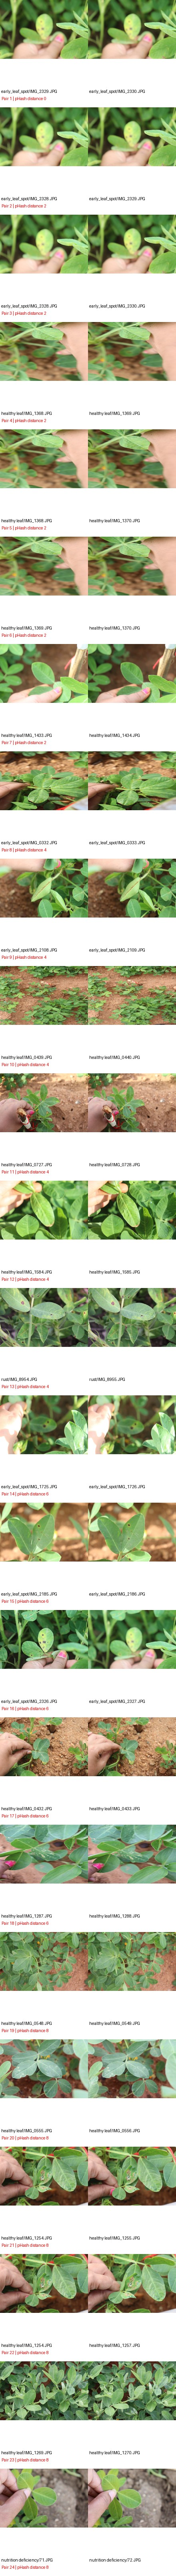

In [6]:
from pathlib import Path
from IPython.display import display, Image

contact_sheet = Path(
    "/content/drive/MyDrive/final_year_project/groundnut/near_duplicate_contact_sheet.jpg"
)

if not contact_sheet.is_file():
    raise FileNotFoundError(f"Contact sheet not found: {contact_sheet}")

display(Image(filename=str(contact_sheet)))

In [7]:
from pathlib import Path
from collections import defaultdict
import shutil
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
pairs_path = project_dir / "near_duplicate_candidates.csv"
review_dir = project_dir / "near_duplicate_review"

if not pairs_path.is_file():
    raise FileNotFoundError(f"Candidate list not found: {pairs_path}")

pairs_df = pd.read_csv(pairs_path)
if pairs_df.empty:
    raise ValueError("The candidate list is empty; nothing to move.")

# Confirm all reviewed pairs are within the same class.
cross_label = pairs_df[pairs_df["label_a"] != pairs_df["label_b"]]
if not cross_label.empty:
    raise ValueError("Cross-label pairs were found. Review them separately; nothing was moved.")

# Build connected duplicate groups from the reviewed pair list.
parent = {}

def find(path):
    parent.setdefault(path, path)
    if parent[path] != path:
        parent[path] = find(parent[path])
    return parent[path]

def union(path_a, path_b):
    root_a, root_b = find(path_a), find(path_b)
    if root_a != root_b:
        parent[root_b] = root_a

for row in pairs_df.itertuples(index=False):
    union(row.path_a, row.path_b)

groups = defaultdict(set)
for relative_path in parent:
    groups[find(relative_path)].add(relative_path)

duplicate_groups = [sorted(paths) for paths in groups.values() if len(paths) > 1]

# Keep the lexicographically first path in each group; move remaining copies aside.
move_plan = []
for group_id, paths in enumerate(sorted(duplicate_groups), start=1):
    keep_path = paths[0]
    for relative_path in paths[1:]:
        source = dataset_dir / relative_path
        destination = review_dir / relative_path
        if not source.is_file():
            raise FileNotFoundError(f"Expected duplicate image is missing: {source}")
        if destination.exists():
            raise FileExistsError(f"Review destination already exists: {destination}")
        move_plan.append((group_id, relative_path, keep_path, source, destination))

print(f"Confirmed duplicate groups: {len(duplicate_groups)}")
print(f"Extra copies to move: {len(move_plan)}")
for group_id, relative_path, keep_path, _, _ in move_plan:
    print(f"  Group {group_id}: move {relative_path} (keep {keep_path})")

# Perform the reviewed, reversible moves.
log_rows = []
for group_id, relative_path, keep_path, source, destination in move_plan:
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.move(str(source), str(destination))
    log_rows.append({
        "group_id": group_id,
        "moved_relative_path": relative_path,
        "kept_relative_path": keep_path,
        "review_copy_path": str(destination),
    })

log_path = project_dir / "near_duplicate_cleanup_log.csv"
pd.DataFrame(log_rows).to_csv(log_path, index=False)

remaining_images = sum(
    1 for path in dataset_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
    }
)

print(f"\nImages remaining in dataset: {remaining_images:,}")
print(f"Moved copies preserved in: {review_dir}")
print(f"Cleanup log: {log_path}")

Confirmed duplicate groups: 19
Extra copies to move: 22
  Group 1: move Raw_Data/early_leaf_spot/IMG_0333.JPG (keep Raw_Data/early_leaf_spot/IMG_0332.JPG)
  Group 2: move Raw_Data/early_leaf_spot/IMG_1726.JPG (keep Raw_Data/early_leaf_spot/IMG_1725.JPG)
  Group 3: move Raw_Data/early_leaf_spot/IMG_2109.JPG (keep Raw_Data/early_leaf_spot/IMG_2108.JPG)
  Group 4: move Raw_Data/early_leaf_spot/IMG_2186.JPG (keep Raw_Data/early_leaf_spot/IMG_2185.JPG)
  Group 5: move Raw_Data/early_leaf_spot/IMG_2327.JPG (keep Raw_Data/early_leaf_spot/IMG_2326.JPG)
  Group 6: move Raw_Data/early_leaf_spot/IMG_2329.JPG (keep Raw_Data/early_leaf_spot/IMG_2328.JPG)
  Group 6: move Raw_Data/early_leaf_spot/IMG_2330.JPG (keep Raw_Data/early_leaf_spot/IMG_2328.JPG)
  Group 7: move Raw_Data/healthy leaf/IMG_0433.JPG (keep Raw_Data/healthy leaf/IMG_0432.JPG)
  Group 8: move Raw_Data/healthy leaf/IMG_0440.JPG (keep Raw_Data/healthy leaf/IMG_0439.JPG)
  Group 9: move Raw_Data/healthy leaf/IMG_0549.JPG (keep Raw_Data

In [8]:
!pip -q install ImageHash

from pathlib import Path
from collections import defaultdict
from PIL import Image, ImageOps, ImageEnhance, ImageDraw
import imagehash
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
threshold = 6
preview_limit = 60

image_paths = sorted(
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

# Hash each original image.
valid_paths, original_hashes, unreadable = [], [], []

for i, path in enumerate(image_paths, start=1):
    try:
        with Image.open(path) as image:
            value = int(str(imagehash.phash(image.convert("RGB"))), 16)
        valid_paths.append(path)
        original_hashes.append(value)
    except Exception as error:
        unreadable.append((path, str(error)))

    if i % 250 == 0 or i == len(image_paths):
        print(f"Hashed originals {i:,}/{len(image_paths):,}")

# BK-tree for fast lookup of similar hashes.
nodes = {}

def hamming(a, b):
    return (a ^ b).bit_count()

def insert_hash(value, image_index):
    if not nodes:
        nodes[value] = {"indices": [image_index], "children": {}}
        return

    current = value
    while True:
        distance = hamming(value, current)
        node = nodes[current]
        if distance == 0:
            node["indices"].append(image_index)
            return
        child = node["children"].get(distance)
        if child is None:
            node["children"][distance] = value
            nodes[value] = {"indices": [image_index], "children": {}}
            return
        current = child

def query_hash(value, max_distance):
    if not nodes:
        return []
    matches = []
    stack = [next(iter(nodes))]
    while stack:
        current = stack.pop()
        distance = hamming(value, current)
        if distance <= max_distance:
            matches.extend((idx, distance) for idx in nodes[current]["indices"])
        for edge, child in nodes[current]["children"].items():
            if distance - max_distance <= edge <= distance + max_distance:
                stack.append(child)
    return matches

for index, value in enumerate(original_hashes):
    insert_hash(value, index)

# Compare transformed versions of each image with originals from the whole dataset.
best_matches = {}

for i, path in enumerate(valid_paths):
    try:
        with Image.open(path) as source:
            original = source.convert("RGB")
            variants = [
                ("horizontal_flip", ImageOps.mirror(original)),
                ("vertical_flip", ImageOps.flip(original)),
                ("rotate_90", original.rotate(90, expand=True)),
                ("rotate_180", original.rotate(180, expand=True)),
                ("rotate_270", original.rotate(270, expand=True)),
                ("brightness_0.8", ImageEnhance.Brightness(original).enhance(0.8)),
                ("brightness_1.2", ImageEnhance.Brightness(original).enhance(1.2)),
                ("contrast_0.8", ImageEnhance.Contrast(original).enhance(0.8)),
                ("contrast_1.2", ImageEnhance.Contrast(original).enhance(1.2)),
            ]

            for transform_name, variant in variants:
                value = int(str(imagehash.phash(variant)), 16)
                for j, distance in query_hash(value, threshold):
                    if i == j:
                        continue

                    pair = tuple(sorted((i, j)))
                    candidate = {
                        "image_a_index": pair[0],
                        "image_b_index": pair[1],
                        "phash_distance": distance,
                        "matched_transform": transform_name,
                    }
                    previous = best_matches.get(pair)
                    if previous is None or distance < previous["phash_distance"]:
                        best_matches[pair] = candidate
    except Exception as error:
        unreadable.append((path, str(error)))

    if (i + 1) % 100 == 0 or i + 1 == len(valid_paths):
        print(f"Checked transformed variants {i + 1:,}/{len(valid_paths):,}")

pairs = []
for match in best_matches.values():
    path_a = valid_paths[match["image_a_index"]]
    path_b = valid_paths[match["image_b_index"]]
    pairs.append({
        "path_a": str(path_a.relative_to(dataset_dir)),
        "label_a": path_a.parent.name,
        "path_b": str(path_b.relative_to(dataset_dir)),
        "label_b": path_b.parent.name,
        "phash_distance": match["phash_distance"],
        "matched_transform": match["matched_transform"],
        "cross_label": path_a.parent.name != path_b.parent.name,
    })

pairs.sort(key=lambda row: (row["phash_distance"], row["path_a"], row["path_b"]))

pairs_path = project_dir / "augmentation_family_candidates.csv"
pd.DataFrame(pairs).to_csv(pairs_path, index=False)

print(f"\nImages checked: {len(valid_paths):,}")
print(f"Unreadable/skipped: {len(unreadable):,}")
print(f"Likely augmentation-family pairs (distance ≤ {threshold}): {len(pairs):,}")
print(f"Cross-label pairs: {sum(row['cross_label'] for row in pairs):,}")
print(f"Candidate list: {pairs_path}")

if pairs:
    shown_pairs = pairs[:preview_limit]
    cell_w, cell_h, label_h = 220, 220, 58
    sheet = Image.new(
        "RGB",
        (cell_w * 2, (cell_h + label_h) * len(shown_pairs)),
        "white",
    )
    draw = ImageDraw.Draw(sheet)

    for index, row in enumerate(shown_pairs):
        y = index * (cell_h + label_h)

        for col, relative_path in enumerate((row["path_a"], row["path_b"])):
            path = dataset_dir / relative_path
            with Image.open(path) as image:
                thumb = ImageOps.contain(image.convert("RGB"), (cell_w, cell_h))
            x = col * cell_w
            sheet.paste(thumb, (x, y))
            draw.text(
                (x + 3, y + cell_h + 2),
                f"{path.parent.name}/{path.name}"[:34],
                fill="black",
            )

        draw.text(
            (4, y + cell_h + 20),
            f"Pair {index + 1} | distance {row['phash_distance']} | {row['matched_transform']}",
            fill="red",
        )

    sheet_path = project_dir / "augmentation_family_contact_sheet.jpg"
    sheet.save(sheet_path, quality=90)
    print(f"Contact sheet (first {len(shown_pairs)} pairs): {sheet_path}")
else:
    print("No augmentation-family candidates found at this threshold.")


Hashed originals 250/3,036
Hashed originals 500/3,036
Hashed originals 750/3,036
Hashed originals 1,000/3,036
Hashed originals 1,250/3,036
Hashed originals 1,500/3,036
Hashed originals 1,750/3,036
Hashed originals 2,000/3,036
Hashed originals 2,250/3,036
Hashed originals 2,500/3,036
Hashed originals 2,750/3,036
Hashed originals 3,000/3,036
Hashed originals 3,036/3,036


KeyError: 15549072369778467083

In [9]:
!pip -q install ImageHash

from pathlib import Path
from PIL import Image, ImageOps, ImageEnhance, ImageDraw
import imagehash
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
threshold = 6
preview_limit = 60

image_paths = sorted(
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

valid_paths, original_hashes, unreadable = [], [], []

for i, path in enumerate(image_paths, start=1):
    try:
        with Image.open(path) as image:
            value = int(str(imagehash.phash(image.convert("RGB"))), 16)
        valid_paths.append(path)
        original_hashes.append(value)
    except Exception as error:
        unreadable.append((path, str(error)))

    if i % 250 == 0 or i == len(image_paths):
        print(f"Hashed originals {i:,}/{len(image_paths):,}")

def hamming(a, b):
    return (a ^ b).bit_count()

# BK-tree nodes are objects, so repeated hash values are stored safely.
class BKNode:
    def __init__(self, value, image_index):
        self.value = value
        self.indices = [image_index]
        self.children = {}

root = None

def insert_hash(value, image_index):
    global root

    if root is None:
        root = BKNode(value, image_index)
        return

    current = root
    while True:
        distance = hamming(value, current.value)
        if distance == 0:
            current.indices.append(image_index)
            return
        if distance not in current.children:
            current.children[distance] = BKNode(value, image_index)
            return
        current = current.children[distance]

def query_hash(value, max_distance):
    if root is None:
        return []

    matches = []
    stack = [root]

    while stack:
        current = stack.pop()
        distance = hamming(value, current.value)

        if distance <= max_distance:
            matches.extend((idx, distance) for idx in current.indices)

        low = distance - max_distance
        high = distance + max_distance
        for edge, child in current.children.items():
            if low <= edge <= high:
                stack.append(child)

    return matches

for index, value in enumerate(original_hashes):
    insert_hash(value, index)

best_matches = {}

for i, path in enumerate(valid_paths):
    try:
        with Image.open(path) as source:
            original = source.convert("RGB")
            variants = [
                ("horizontal_flip", ImageOps.mirror(original)),
                ("vertical_flip", ImageOps.flip(original)),
                ("rotate_90", original.rotate(90, expand=True)),
                ("rotate_180", original.rotate(180, expand=True)),
                ("rotate_270", original.rotate(270, expand=True)),
                ("brightness_0.8", ImageEnhance.Brightness(original).enhance(0.8)),
                ("brightness_1.2", ImageEnhance.Brightness(original).enhance(1.2)),
                ("contrast_0.8", ImageEnhance.Contrast(original).enhance(0.8)),
                ("contrast_1.2", ImageEnhance.Contrast(original).enhance(1.2)),
            ]

            for transform_name, variant in variants:
                value = int(str(imagehash.phash(variant)), 16)

                for j, distance in query_hash(value, threshold):
                    if i == j:
                        continue

                    pair = tuple(sorted((i, j)))
                    previous = best_matches.get(pair)

                    if previous is None or distance < previous["phash_distance"]:
                        best_matches[pair] = {
                            "image_a_index": pair[0],
                            "image_b_index": pair[1],
                            "phash_distance": distance,
                            "matched_transform": transform_name,
                        }

    except Exception as error:
        unreadable.append((path, str(error)))

    if (i + 1) % 100 == 0 or i + 1 == len(valid_paths):
        print(f"Checked transformed variants {i + 1:,}/{len(valid_paths):,}")

pairs = []
for match in best_matches.values():
    path_a = valid_paths[match["image_a_index"]]
    path_b = valid_paths[match["image_b_index"]]

    pairs.append({
        "path_a": str(path_a.relative_to(dataset_dir)),
        "label_a": path_a.parent.name,
        "path_b": str(path_b.relative_to(dataset_dir)),
        "label_b": path_b.parent.name,
        "phash_distance": match["phash_distance"],
        "matched_transform": match["matched_transform"],
        "cross_label": path_a.parent.name != path_b.parent.name,
    })

pairs.sort(key=lambda row: (row["phash_distance"], row["path_a"], row["path_b"]))

pairs_path = project_dir / "augmentation_family_candidates.csv"
pd.DataFrame(pairs).to_csv(pairs_path, index=False)

print(f"\nImages checked: {len(valid_paths):,}")
print(f"Unreadable/skipped: {len(unreadable):,}")
print(f"Likely augmentation-family pairs (distance ≤ {threshold}): {len(pairs):,}")
print(f"Cross-label pairs: {sum(row['cross_label'] for row in pairs):,}")
print(f"Candidate list: {pairs_path}")

if pairs:
    shown_pairs = pairs[:preview_limit]
    cell_w, cell_h, label_h = 220, 220, 58
    sheet = Image.new(
        "RGB",
        (cell_w * 2, (cell_h + label_h) * len(shown_pairs)),
        "white",
    )
    draw = ImageDraw.Draw(sheet)

    for index, row in enumerate(shown_pairs):
        y = index * (cell_h + label_h)

        for col, relative_path in enumerate((row["path_a"], row["path_b"])):
            path = dataset_dir / relative_path
            with Image.open(path) as image:
                thumb = ImageOps.contain(image.convert("RGB"), (cell_w, cell_h))

            x = col * cell_w
            sheet.paste(thumb, (x, y))
            draw.text(
                (x + 3, y + cell_h + 2),
                f"{path.parent.name}/{path.name}"[:34],
                fill="black",
            )

        draw.text(
            (4, y + cell_h + 20),
            f"Pair {index + 1} | distance {row['phash_distance']} | {row['matched_transform']}",
            fill="red",
        )

    sheet_path = project_dir / "augmentation_family_contact_sheet.jpg"
    sheet.save(sheet_path, quality=90)
    print(f"Contact sheet (first {len(shown_pairs)} pairs): {sheet_path}")
else:
    print("No augmentation-family candidates found at this threshold.")

Hashed originals 250/3,036
Hashed originals 500/3,036
Hashed originals 750/3,036
Hashed originals 1,000/3,036
Hashed originals 1,250/3,036
Hashed originals 1,500/3,036
Hashed originals 1,750/3,036
Hashed originals 2,000/3,036
Hashed originals 2,250/3,036
Hashed originals 2,500/3,036
Hashed originals 2,750/3,036
Hashed originals 3,000/3,036
Hashed originals 3,036/3,036
Checked transformed variants 100/3,036
Checked transformed variants 200/3,036
Checked transformed variants 300/3,036
Checked transformed variants 400/3,036
Checked transformed variants 500/3,036
Checked transformed variants 600/3,036
Checked transformed variants 700/3,036
Checked transformed variants 800/3,036
Checked transformed variants 900/3,036
Checked transformed variants 1,000/3,036
Checked transformed variants 1,100/3,036
Checked transformed variants 1,200/3,036
Checked transformed variants 1,300/3,036
Checked transformed variants 1,400/3,036
Checked transformed variants 1,500/3,036
Checked transformed variants 1,6

In [13]:
!pip -q install ImageHash

from pathlib import Path
from collections import defaultdict
import hashlib
import imagehash
import pandas as pd
from PIL import Image

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
manifest_path = project_dir / "split_manifest.csv"

if not manifest_path.is_file():
    raise FileNotFoundError(f"Split manifest not found: {manifest_path}")

manifest = pd.read_csv(manifest_path)
required_columns = {"relative_path", "label", "split"}
if not required_columns.issubset(manifest.columns):
    raise ValueError(f"Manifest must contain columns: {sorted(required_columns)}")

# Hash each manifest image and group identical bytes.
records = []
for i, row in enumerate(manifest.itertuples(index=False), start=1):
    path = dataset_dir / row.relative_path
    if not path.is_file():
        raise FileNotFoundError(f"Manifest image is missing: {path}")

    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    with Image.open(path) as image:
        phash = int(str(imagehash.phash(image.convert("RGB"))), 16)

    records.append({
        "relative_path": row.relative_path,
        "label": row.label,
        "split": row.split,
        "sha256": digest.hexdigest(),
        "phash": phash,
    })

    if i % 250 == 0 or i == len(manifest):
        print(f"Checked {i:,}/{len(manifest):,} manifest images")

records_df = pd.DataFrame(records)

# Report exact byte-for-byte duplicates crossing split boundaries.
exact_rows = []
for digest, group in records_df.groupby("sha256"):
    if group["split"].nunique() > 1:
        entries = group.to_dict("records")
        for i in range(len(entries)):
            for j in range(i + 1, len(entries)):
                if entries[i]["split"] != entries[j]["split"]:
                    exact_rows.append({
                        "path_a": entries[i]["relative_path"],
                        "label_a": entries[i]["label"],
                        "split_a": entries[i]["split"],
                        "path_b": entries[j]["relative_path"],
                        "label_b": entries[j]["label"],
                        "split_b": entries[j]["split"],
                        "sha256": digest,
                    })

exact_path = project_dir / "cross_split_exact_duplicates.csv"
pd.DataFrame(exact_rows).to_csv(exact_path, index=False)

# BK-tree for cross-split perceptual-hash comparisons.
def hamming(a, b):
    return (a ^ b).bit_count()

class BKNode:
    def __init__(self, value, record):
        self.value = value
        self.records = [record]
        self.children = {}

root = None

def insert_hash(value, record):
    global root
    if root is None:
        root = BKNode(value, record)
        return

    node = root
    while True:
        distance = hamming(value, node.value)
        if distance == 0:
            node.records.append(record)
            return
        if distance not in node.children:
            node.children[distance] = BKNode(value, record)
            return
        node = node.children[distance]

def query_hash(value, max_distance):
    if root is None:
        return []

    matches = []
    stack = [root]
    while stack:
        node = stack.pop()
        distance = hamming(value, node.value)
        if distance <= max_distance:
            matches.extend((record, distance) for record in node.records)

        low, high = distance - max_distance, distance + max_distance
        for edge, child in node.children.items():
            if low <= edge <= high:
                stack.append(child)

    return matches

split_order = ["train", "validation", "internal_test"]
phash_threshold = 8
near_rows = []

# Query each split against all earlier splits, then add it to the index.
for split_name in split_order:
    split_records = records_df[records_df["split"] == split_name].to_dict("records")

    for record in split_records:
        for previous, distance in query_hash(record["phash"], phash_threshold):
            if record["relative_path"] == previous["relative_path"]:
                continue

            near_rows.append({
                "path_a": previous["relative_path"],
                "label_a": previous["label"],
                "split_a": previous["split"],
                "path_b": record["relative_path"],
                "label_b": record["label"],
                "split_b": record["split"],
                "phash_distance": distance,
                "cross_label": previous["label"] != record["label"],
            })

    for record in split_records:
        insert_hash(record["phash"], record)

near_rows.sort(key=lambda row: (row["phash_distance"], row["path_a"], row["path_b"]))
near_path = project_dir / "cross_split_phash_candidates.csv"
pd.DataFrame(near_rows).to_csv(near_path, index=False)

print("\nCross-split audit results:")
print(f"Exact duplicate pairs: {len(exact_rows):,}")
print(f"Near-duplicate candidates (pHash distance ≤ {phash_threshold}): {len(near_rows):,}")
print(f"Cross-split exact report: {exact_path}")
print(f"Cross-split pHash report: {near_path}")

if exact_rows:
    print("\nExact cross-split matches:")
    for row in exact_rows[:30]:
        print(f"  {row['split_a']} ↔ {row['split_b']}: {row['path_a']} ↔ {row['path_b']}")

if near_rows:
    print("\nFirst cross-split pHash candidates:")
    for row in near_rows[:30]:
        print(
            f"  d={row['phash_distance']} | "
            f"{row['split_a']} ↔ {row['split_b']} | "
            f"{row['path_a']} ↔ {row['path_b']}"
        )

Checked 250/3,036 manifest images
Checked 500/3,036 manifest images
Checked 750/3,036 manifest images
Checked 1,000/3,036 manifest images
Checked 1,250/3,036 manifest images
Checked 1,500/3,036 manifest images
Checked 1,750/3,036 manifest images
Checked 2,000/3,036 manifest images
Checked 2,250/3,036 manifest images
Checked 2,500/3,036 manifest images
Checked 2,750/3,036 manifest images
Checked 3,000/3,036 manifest images
Checked 3,036/3,036 manifest images

Cross-split audit results:
Exact duplicate pairs: 0
Near-duplicate candidates (pHash distance ≤ 8): 0
Cross-split exact report: /content/drive/MyDrive/final_year_project/groundnut/cross_split_exact_duplicates.csv
Cross-split pHash report: /content/drive/MyDrive/final_year_project/groundnut/cross_split_phash_candidates.csv


In [12]:
from pathlib import Path
import json
import pandas as pd
from sklearn.model_selection import train_test_split

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

records = [
    {
        "relative_path": str(path.relative_to(dataset_dir)),
        "label": path.parent.name,
    }
    for path in sorted(dataset_dir.rglob("*"))
    if path.is_file() and path.suffix.lower() in image_extensions
]

df = pd.DataFrame(records)
if df.empty:
    raise ValueError(f"No images found under {dataset_dir}")

print(f"Images included: {len(df):,}")
print("\nClass counts:")
print(df["label"].value_counts().sort_index().to_string())

train_df, holdout_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["label"]
)
val_df, test_df = train_test_split(
    holdout_df, test_size=0.50, random_state=43, stratify=holdout_df["label"]
)

train_df = train_df.assign(split="train")
val_df = val_df.assign(split="validation")
test_df = test_df.assign(split="internal_test")

manifest = pd.concat([train_df, val_df, test_df], ignore_index=True)
manifest = manifest[["relative_path", "label", "split"]].sort_values(
    ["split", "label", "relative_path"]
).reset_index(drop=True)

manifest_path = project_dir / "split_manifest.csv"
manifest.to_csv(manifest_path, index=False)

split_counts = {}
for split_name in ("train", "validation", "internal_test"):
    subset = manifest[manifest["split"] == split_name]
    split_counts[split_name] = {
        "total": int(len(subset)),
        "by_class": {
            str(label): int(count)
            for label, count in subset["label"].value_counts().sort_index().items()
        },
    }

config = {
    "dataset_root": str(dataset_dir),
    "manifest": str(manifest_path),
    "seeds": {"train_holdout": 42, "validation_test": 43},
    "target_proportions": {
        "train": 0.70,
        "validation": 0.15,
        "internal_test": 0.15,
    },
    "image_count": int(len(manifest)),
    "class_names": sorted(manifest["label"].unique().tolist()),
    "split_counts": split_counts,
    "cleaning_notes": {
        "exact_duplicate_groups_found": 0,
        "reviewed_near_duplicate_groups_removed": 19,
        "extra_near_duplicate_copies_moved_to_review": 22,
        "augmentation_family_candidates_found": 0,
    },
}

config_path = project_dir / "split_config.json"
config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print("\nSplit totals:")
for split_name, details in split_counts.items():
    print(f"  {split_name}: {details['total']:,}")

print(f"\nManifest saved: {manifest_path}")
print(f"Split config saved: {config_path}")

Images included: 3,036

Class counts:
label
early_leaf_spot         878
healthy leaf            916
late leaf spot          689
nutrition deficiency    328
rust                    225

Split totals:
  train: 2,125
  validation: 455
  internal_test: 456

Manifest saved: /content/drive/MyDrive/final_year_project/groundnut/split_manifest.csv
Split config saved: /content/drive/MyDrive/final_year_project/groundnut/split_config.json


In [14]:
from pathlib import Path
import json
import pandas as pd
from PIL import Image

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
dataset_dir = project_dir / "dataset"
manifest_path = project_dir / "split_manifest.csv"
cache_dir = Path("/content/groundnut_cache")
cache_manifest_path = project_dir / "split_manifest_with_cache.csv"
config_path = project_dir / "preprocessing_config.json"

if not manifest_path.is_file():
    raise FileNotFoundError(f"Split manifest not found: {manifest_path}")

manifest = pd.read_csv(manifest_path)
max_side = 1024

cache_dir.mkdir(parents=True, exist_ok=True)
cache_paths = []
errors = []

for i, row in enumerate(manifest.itertuples(index=False), start=1):
    source = dataset_dir / row.relative_path
    cache_relative = Path(row.relative_path).with_suffix(".jpg")
    destination = cache_dir / cache_relative

    try:
        if not source.is_file():
            raise FileNotFoundError(f"Source image missing: {source}")

        destination.parent.mkdir(parents=True, exist_ok=True)

        if not destination.is_file():
            with Image.open(source) as image:
                image = image.convert("RGB")
                width, height = image.size
                scale = min(max_side / max(width, height), 1.0)
                new_size = (
                    max(1, round(width * scale)),
                    max(1, round(height * scale)),
                )
                image = image.resize(new_size, Image.Resampling.LANCZOS)
                image.save(destination, format="JPEG", quality=95, optimize=True)

        cache_paths.append(str(cache_relative))
    except Exception as error:
        cache_paths.append(None)
        errors.append((row.relative_path, str(error)))

    if i % 250 == 0 or i == len(manifest):
        print(f"Cached {i:,}/{len(manifest):,} images")

manifest["cache_relative_path"] = cache_paths
manifest.to_csv(cache_manifest_path, index=False)

config = {
    "source_manifest": str(manifest_path),
    "cached_manifest": str(cache_manifest_path),
    "local_cache_dir": str(cache_dir),
    "cache_format": "JPEG",
    "cache_quality": 95,
    "cache_max_long_edge": max_side,
    "cache_resize_filter": "Lanczos",
    "color_mode": "RGB",
    "model_input_size": [448, 448],
    "full_image_view": "Preserve aspect ratio; resize to fit 448x448 and pad remaining area.",
    "tile_views": {
        "method": "Two square crops from the resized landscape image, then resize each to 448x448.",
        "overlap": "Approximately 50% horizontally for 1200x800 source images.",
    },
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225],
        "note": "ImageNet normalization; apply consistently in training, validation, testing, and inference.",
    },
    "errors": len(errors),
}

config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

cache_files = [
    path for path in cache_dir.rglob("*.jpg")
    if path.is_file()
]

print(f"\nManifest rows: {len(manifest):,}")
print(f"Cache images present: {len(cache_files):,}")
print(f"Cache directory: {cache_dir}")
print(f"Cached manifest saved: {cache_manifest_path}")
print(f"Preprocessing config saved: {config_path}")
print(f"Errors: {len(errors):,}")

if errors:
    print("\nFirst cache errors:")
    for relative_path, error in errors[:20]:
        print(f"  {relative_path}: {error}")

Cached 250/3,036 images
Cached 500/3,036 images
Cached 750/3,036 images
Cached 1,000/3,036 images
Cached 1,250/3,036 images
Cached 1,500/3,036 images
Cached 1,750/3,036 images
Cached 2,000/3,036 images
Cached 2,250/3,036 images
Cached 2,500/3,036 images
Cached 2,750/3,036 images
Cached 3,000/3,036 images
Cached 3,036/3,036 images

Manifest rows: 3,036
Cache images present: 3,036
Cache directory: /content/groundnut_cache
Cached manifest saved: /content/drive/MyDrive/final_year_project/groundnut/split_manifest_with_cache.csv
Preprocessing config saved: /content/drive/MyDrive/final_year_project/groundnut/preprocessing_config.json
Errors: 0


In [15]:
import json
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image, ImageOps
from torchvision import models, transforms

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
cache_dir = Path("/content/groundnut_cache")
manifest_path = project_dir / "split_manifest_with_cache.csv"
checkpoint_dir = project_dir / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

if not manifest_path.is_file():
    raise FileNotFoundError(f"Cached split manifest not found: {manifest_path}")

manifest = pd.read_csv(manifest_path)
required = {"cache_relative_path", "label", "split"}
if not required.issubset(manifest.columns):
    raise ValueError(f"Manifest needs columns: {sorted(required)}")

class_names = sorted(manifest["label"].unique().tolist())
class_to_idx = {name: index for index, name in enumerate(class_names)}

# ImageNet normalization, matching preprocessing_config.json.
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
input_size = 448

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=25),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.90, 1.10)),
    transforms.ColorJitter(brightness=0.18, contrast=0.18, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

def make_full_view(image):
    image = ImageOps.contain(image, (input_size, input_size), method=Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (input_size, input_size), (0, 0, 0))
    x = (input_size - image.width) // 2
    y = (input_size - image.height) // 2
    canvas.paste(image, (x, y))
    return canvas

def make_tile_views(image):
    width, height = image.size
    side = min(width, height)

    if width >= height:
        starts = [0, width - side]
        return [image.crop((x, 0, x + side, side)) for x in starts]
    else:
        starts = [0, height - side]
        return [image.crop((0, y, side, y + side)) for y in starts]

class GroundnutDataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.training = training
        self.transform = train_transform if training else eval_transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = cache_dir / row["cache_relative_path"]

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        views = [make_full_view(image)] + make_tile_views(image)
        views = torch.stack([self.transform(view) for view in views])
        label = class_to_idx[row["label"]]
        return views, label

train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "validation"].copy()

for _, row in manifest.iterrows():
    if not (cache_dir / row["cache_relative_path"]).is_file():
        raise FileNotFoundError(
            f"Cached image missing: {cache_dir / row['cache_relative_path']}"
        )

train_dataset = GroundnutDataset(train_df, training=True)
val_dataset = GroundnutDataset(val_df, training=False)

# Equalize expected class sampling frequency in training.
train_labels = train_df["label"].map(class_to_idx).to_numpy()
class_counts = train_df["label"].value_counts().to_dict()
sample_weights = torch.tensor(
    [1.0 / class_counts[label] for label in train_df["label"]],
    dtype=torch.double,
)
train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True,
)

batch_size = 4
num_workers = 2
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=train_sampler,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)

class GroundnutResNet50Fusion(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()

        weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        resnet = models.resnet50(weights=weights)

        self.stem = nn.Sequential(
            resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool
        )
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4

        fusion_dim = 256
        self.scale_projection = nn.ModuleList([
            nn.Linear(512, fusion_dim),
            nn.Linear(1024, fusion_dim),
            nn.Linear(2048, fusion_dim),
        ])
        self.scale_attention = nn.MultiheadAttention(
            fusion_dim, num_heads=4, batch_first=True
        )
        self.scale_norm = nn.LayerNorm(fusion_dim)

        self.spatial_projection = nn.Conv2d(2048, fusion_dim, kernel_size=1)
        self.spatial_attention = nn.MultiheadAttention(
            fusion_dim, num_heads=4, batch_first=True
        )
        self.spatial_norm = nn.LayerNorm(fusion_dim)

        self.embedding = nn.Sequential(
            nn.Linear(fusion_dim * 2, 512),
            nn.GELU(),
            nn.Dropout(0.30),
        )
        self.classifier = nn.Linear(512, num_classes)

    def encode_single_view(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        feature2 = self.layer2(x)
        feature3 = self.layer3(feature2)
        feature4 = self.layer4(feature3)

        # Multi-scale global features from ResNet stages 2, 3, and 4.
        pooled = [
            F.adaptive_avg_pool2d(feature, 1).flatten(1)
            for feature in (feature2, feature3, feature4)
        ]
        scale_tokens = torch.stack([
            projection(feature)
            for projection, feature in zip(self.scale_projection, pooled)
        ], dim=1)
        scale_attended, _ = self.scale_attention(
            scale_tokens, scale_tokens, scale_tokens, need_weights=False
        )
        scale_feature = self.scale_norm(scale_tokens + scale_attended).mean(dim=1)

        # Spatial self-attention over a compact 7x7 layer-4 feature map.
        spatial = F.adaptive_avg_pool2d(feature4, (7, 7))
        spatial = self.spatial_projection(spatial).flatten(2).transpose(1, 2)
        spatial_attended, _ = self.spatial_attention(
            spatial, spatial, spatial, need_weights=False
        )
        spatial_feature = self.spatial_norm(spatial + spatial_attended).mean(dim=1)

        return self.embedding(torch.cat([scale_feature, spatial_feature], dim=1))

    def encode_views(self, views):
        # Input shape: batch × views × channels × height × width.
        batch, view_count, channels, height, width = views.shape
        flattened = views.reshape(batch * view_count, channels, height, width)
        features = self.encode_single_view(flattened)
        features = features.reshape(batch, view_count, -1)
        return features.mean(dim=1)

    def forward(self, views):
        features = self.encode_views(views)
        return self.classifier(features), features

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GroundnutResNet50Fusion(
    num_classes=len(class_names),
    pretrained=True,
).to(device)

model_config = {
    "architecture": "GroundnutResNet50Fusion",
    "backbone": "ResNet50 ImageNet1K V2",
    "class_names": class_names,
    "input_size": input_size,
    "views": ["full_leaf", "overlapping_tile_left", "overlapping_tile_right"],
    "fusion": "ResNet layer2/layer3/layer4 multi-scale attention plus layer4 spatial self-attention",
    "balanced_sampler": True,
    "batch_size": batch_size,
}

(project_dir / "model_config.json").write_text(
    json.dumps(model_config, indent=2),
    encoding="utf-8",
)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training counts by class:", class_counts)
print("Balanced sampler: enabled for training only")
print("Views per image: full-leaf view + 2 overlapping tiles")
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Model config saved:", project_dir / "model_config.json")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s]


Device: cuda
GPU: Tesla T4
Classes: ['early_leaf_spot', 'healthy leaf', 'late leaf spot', 'nutrition deficiency', 'rust']
Training images: 2125
Validation images: 455
Training counts by class: {'healthy leaf': 641, 'early_leaf_spot': 615, 'late leaf spot': 482, 'nutrition deficiency': 230, 'rust': 157}
Balanced sampler: enabled for training only
Views per image: full-leaf view + 2 overlapping tiles
Model parameters: 25,743,429
Model config saved: /content/drive/MyDrive/final_year_project/groundnut/model_config.json


In [20]:
import os
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

if "model" not in globals() or "train_loader" not in globals() or "val_loader" not in globals():
    raise RuntimeError("Run the model and data-loader setup cell first.")

epochs = 25
patience = 7
min_delta = 0.001
learning_rate_backbone = 1e-4
learning_rate_head = 5e-4
weight_decay = 1e-4

last_path = checkpoint_dir / "last_checkpoint.pt"
best_path = checkpoint_dir / "best_model.pt"
history_path = project_dir / "training_history.csv"

backbone_parameters = (
    list(model.stem.parameters())
    + list(model.layer1.parameters())
    + list(model.layer2.parameters())
    + list(model.layer3.parameters())
    + list(model.layer4.parameters())
)
backbone_ids = {id(parameter) for parameter in backbone_parameters}
head_parameters = [
    parameter for parameter in model.parameters()
    if id(parameter) not in backbone_ids
]

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": learning_rate_backbone},
        {"params": head_parameters, "lr": learning_rate_head},
    ],
    weight_decay=weight_decay,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=epochs
)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.05)

start_epoch = 0
best_macro_f1 = -1.0
epochs_without_improvement = 0
history = []

if last_path.is_file():
    checkpoint = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    start_epoch = int(checkpoint["epoch"])
    best_macro_f1 = float(checkpoint.get("best_macro_f1", -1.0))
    epochs_without_improvement = int(checkpoint.get("epochs_without_improvement", 0))
    history = checkpoint.get("history", [])
    print(f"Resuming after completed epoch {start_epoch}")
else:
    print("No saved training checkpoint found; starting from epoch 1.")

def save_checkpoint(path, payload):
    temporary_path = Path(str(path) + ".tmp")
    torch.save(payload, temporary_path)
    os.replace(temporary_path, path)

for epoch_index in range(start_epoch, epochs):
    epoch_number = epoch_index + 1
    model.train()
    running_loss = 0.0
    train_targets, train_predictions = [], []

    train_progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch_number:02d}/{epochs} train",
        leave=False,
    )

    for views, labels in train_progress:
        views = views.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits, _ = model(views)
        loss = criterion(logits.float(), labels)

        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite training loss at epoch {epoch_number}"
            )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        predictions = logits.argmax(dim=1)
        train_targets.extend(labels.detach().cpu().tolist())
        train_predictions.extend(predictions.detach().cpu().tolist())

        train_progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / len(train_dataset)
    train_accuracy = accuracy_score(train_targets, train_predictions)
    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        labels=list(range(len(class_names))),
        average="macro",
        zero_division=0,
    )

    model.eval()
    val_loss_sum = 0.0
    val_targets, val_predictions = [], []

    val_progress = tqdm(
        val_loader,
        desc=f"Epoch {epoch_number:02d}/{epochs} validation",
        leave=False,
    )

    with torch.no_grad():
        for views, labels in val_progress:
            views = views.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits, _ = model(views)
            loss = criterion(logits.float(), labels)

            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Non-finite validation loss at epoch {epoch_number}"
                )

            val_loss_sum += loss.item() * labels.size(0)
            val_targets.extend(labels.cpu().tolist())
            val_predictions.extend(logits.argmax(dim=1).cpu().tolist())
            val_progress.set_postfix(loss=f"{loss.item():.4f}")

    val_loss = val_loss_sum / len(val_dataset)
    val_accuracy = accuracy_score(val_targets, val_predictions)
    val_balanced_accuracy = balanced_accuracy_score(val_targets, val_predictions)
    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        labels=list(range(len(class_names))),
        average="macro",
        zero_division=0,
    )

    improved = val_macro_f1 > best_macro_f1 + min_delta
    if improved:
        best_macro_f1 = val_macro_f1
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    metrics = {
        "epoch": epoch_number,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_balanced_accuracy": val_balanced_accuracy,
        "validation_macro_f1": val_macro_f1,
        "learning_rate_backbone": optimizer.param_groups[0]["lr"],
        "learning_rate_head": optimizer.param_groups[1]["lr"],
    }
    history.append(metrics)

    print(
        f"Epoch {epoch_number:02d}/{epochs} | "
        f"train loss {train_loss:.4f}, acc {train_accuracy:.4f}, "
        f"macro-F1 {train_macro_f1:.4f} | "
        f"val loss {val_loss:.4f}, acc {val_accuracy:.4f}, "
        f"balanced acc {val_balanced_accuracy:.4f}, "
        f"macro-F1 {val_macro_f1:.4f}"
        f"{' [BEST]' if improved else ''}"
    )

    scheduler.step()

    payload = {
        "epoch": epoch_number,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_macro_f1": best_macro_f1,
        "epochs_without_improvement": epochs_without_improvement,
        "history": history,
        "class_names": class_names,
        "model_config": model_config,
        "validation_metrics": {
            "loss": val_loss,
            "accuracy": val_accuracy,
            "balanced_accuracy": val_balanced_accuracy,
            "macro_f1": val_macro_f1,
        },
    }
    save_checkpoint(last_path, payload)

    if improved:
        save_checkpoint(best_path, payload)

    pd.DataFrame(history).to_csv(history_path, index=False)

    print(f"  Latest checkpoint: {last_path}")
    print(f"  Best checkpoint:   {best_path}")

    if epochs_without_improvement >= patience:
        print(f"Early stopping after {patience} epochs without validation macro-F1 improvement.")
        break

print(f"\nTraining finished. Best checkpoint: {best_path}")
print(f"Training history: {history_path}")

Resuming after completed epoch 7


Epoch 08/25 train:   0%|          | 0/532 [00:00<?, ?it/s]

Epoch 08/25 validation:   0%|          | 0/114 [00:00<?, ?it/s]

Epoch 08/25 | train loss 0.3986, acc 0.9261, macro-F1 0.9249 | val loss 0.4820, acc 0.8901, balanced acc 0.9196, macro-F1 0.9144 [BEST]
  Latest checkpoint: /content/drive/MyDrive/final_year_project/groundnut/checkpoints/last_checkpoint.pt
  Best checkpoint:   /content/drive/MyDrive/final_year_project/groundnut/checkpoints/best_model.pt


Epoch 09/25 train:   0%|          | 0/532 [00:00<?, ?it/s]

...

Epoch 21/25 train:   0%|          | 0/532 [00:00<?, ?it/s]

Epoch 21/25 validation:   0%|          | 0/114 [00:00<?, ?it/s]

Epoch 21/25 | train loss 0.2365, acc 0.9972, macro-F1 0.9971 | val loss 0.4666, acc 0.9209, balanced acc 0.9382, macro-F1 0.9400 [BEST]
  Latest checkpoint: /content/drive/MyDrive/final_year_project/groundnut/checkpoints/last_checkpoint.pt
  Best checkpoint:   /content/drive/MyDrive/final_year_project/groundnut/checkpoints/best_model.pt


Epoch 22/25 train:   0%|          | 0/532 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [19]:
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms
import torch

input_size = 448
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Resize both the full image and tile views to the same model input size.
train_transform = transforms.Compose([
    transforms.Resize(
        (input_size, input_size),
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=25),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.90, 1.10)),
    transforms.ColorJitter(brightness=0.18, contrast=0.18, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (input_size, input_size),
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Recreate datasets so they pick up the corrected transforms.
train_dataset = GroundnutDataset(train_df, training=True)
val_dataset = GroundnutDataset(val_df, training=False)

sample_weights = torch.tensor(
    [1.0 / class_counts[label] for label in train_df["label"]],
    dtype=torch.double,
)
train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=train_sampler,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
)

print("Transforms updated: full and tile views all resize to 448×448.")
print(f"Training batches per epoch: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print("No training checkpoint was created; rerun the training cell to start at epoch 1.")

Transforms updated: full and tile views all resize to 448×448.
Training batches per epoch: 532
Validation batches: 114
No training checkpoint was created; rerun the training cell to start at epoch 1.


In [21]:
import json
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
best_path = project_dir / "checkpoints" / "best_model.pt"

if not best_path.is_file():
    raise FileNotFoundError(f"Best checkpoint not found: {best_path}")

checkpoint = torch.load(best_path, map_location=device, weights_only=False)
checkpoint_classes = checkpoint.get("class_names", class_names)
if list(checkpoint_classes) != list(class_names):
    raise ValueError(
        f"Checkpoint class order {checkpoint_classes} does not match {class_names}"
    )

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(device)
model.eval()

test_df = manifest[manifest["split"] == "internal_test"].copy()
if test_df.empty:
    raise ValueError("No internal_test rows found in the manifest.")

test_dataset = GroundnutDataset(test_df, training=False)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

y_true, y_pred, confidences = [], [], []

with torch.no_grad():
    for batch_index, (views, labels) in enumerate(
        tqdm(test_loader, desc="Internal test evaluation"),
        start=1,
    ):
        views = views.to(device, non_blocking=True)
        logits, _ = model(views)
        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predictions = probabilities.max(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
        confidences.extend(confidence.cpu().tolist())

        if batch_index % 25 == 0 or batch_index == len(test_loader):
            print(f"Evaluated {min(batch_index * batch_size, len(test_dataset)):,}/{len(test_dataset):,}")

labels_index = list(range(len(class_names)))
accuracy = accuracy_score(y_true, y_pred)
balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, labels=labels_index, average="macro", zero_division=0
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=labels_index,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
cm = confusion_matrix(y_true, y_pred, labels=labels_index)

print(f"\nSelected checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
print(f"Internal test images: {len(test_dataset):,}")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")
print(f"Macro-F1:          {macro_f1:.4f}")

print("\nPer-class metrics:")
for class_name in class_names:
    metrics = report_dict[class_name]
    print(
        f"{class_name}: precision={metrics['precision']:.4f}, "
        f"recall={metrics['recall']:.4f}, F1={metrics['f1-score']:.4f}, "
        f"support={int(metrics['support'])}"
    )

print("\nConfusion matrix (rows=true, columns=predicted):")
print(pd.DataFrame(cm, index=class_names, columns=class_names).to_string())

misclassified_rows = []
for i, (true_idx, pred_idx, confidence) in enumerate(zip(y_true, y_pred, confidences)):
    if true_idx != pred_idx:
        row = test_df.iloc[i]
        misclassified_rows.append({
            "relative_path": row["relative_path"],
            "true_label": class_names[true_idx],
            "predicted_label": class_names[pred_idx],
            "confidence": float(confidence),
        })

report = {
    "checkpoint": str(best_path),
    "checkpoint_epoch": int(checkpoint.get("epoch", -1)),
    "test_count": int(len(test_dataset)),
    "accuracy": float(accuracy),
    "balanced_accuracy": float(balanced_accuracy),
    "macro_f1": float(macro_f1),
    "per_class": report_dict,
    "confusion_matrix": cm.tolist(),
    "class_order": class_names,
}

report_path = project_dir / "internal_test_report.json"
confusion_path = project_dir / "internal_test_confusion_matrix.csv"
misclassified_path = project_dir / "internal_test_misclassified.csv"

report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(confusion_path)
pd.DataFrame(misclassified_rows).to_csv(misclassified_path, index=False)

print(f"\nMisclassified images: {len(misclassified_rows):,}")
print(f"Report saved: {report_path}")
print(f"Confusion matrix saved: {confusion_path}")
print(f"Misclassified list saved: {misclassified_path}")

Internal test evaluation:   0%|          | 0/114 [00:00<?, ?it/s]

Evaluated 100/456
Evaluated 200/456
Evaluated 300/456
Evaluated 400/456
Evaluated 456/456

Selected checkpoint epoch: 21
Internal test images: 456
Accuracy:          0.9496
Balanced accuracy: 0.9569
Macro-F1:          0.9611

Per-class metrics:
early_leaf_spot: precision=0.9365, recall=0.8939, F1=0.9147, support=132
healthy leaf: precision=0.9034, recall=0.9493, F1=0.9258, support=138
late leaf spot: precision=0.9904, recall=1.0000, F1=0.9952, support=103
nutrition deficiency: precision=1.0000, recall=1.0000, F1=1.0000, support=49
rust: precision=1.0000, recall=0.9412, F1=0.9697, support=34

Confusion matrix (rows=true, columns=predicted):
                      early_leaf_spot  healthy leaf  late leaf spot  nutrition deficiency  rust
early_leaf_spot                   118            14               0                     0     0
healthy leaf                        7           131               0                     0     0
late leaf spot                      0             0             

In [22]:
from pathlib import Path
from collections import Counter
from PIL import Image, UnidentifiedImageError
import pandas as pd

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
ood_root = Path(
    "/content/drive/MyDrive/final_year_project/Tea/tea_ood_data/plantdoc_extract"
)
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

if not ood_root.is_dir():
    raise FileNotFoundError(f"PlantDoc folder not found: {ood_root}")

image_paths = sorted(
    path for path in ood_root.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

rows = []
unreadable = []
size_counts = Counter()

for i, path in enumerate(image_paths, start=1):
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            width, height = image.size
            image_format = image.format

        relative_path = path.relative_to(ood_root)
        rows.append({
            "relative_path": str(relative_path),
            "class_folder": path.parent.name,
            "width": width,
            "height": height,
            "format": image_format,
            "readable": True,
        })
        size_counts[(width, height)] += 1
    except (UnidentifiedImageError, OSError, ValueError) as error:
        unreadable.append((str(path), str(error)))
        rows.append({
            "relative_path": str(path.relative_to(ood_root)),
            "class_folder": path.parent.name,
            "width": None,
            "height": None,
            "format": None,
            "readable": False,
        })

    if i % 250 == 0 or i == len(image_paths):
        print(f"Inspected {i:,}/{len(image_paths):,} PlantDoc images")

report_path = project_dir / "plantdoc_ood_source_inventory.csv"
report_df = pd.DataFrame(rows)
report_df.to_csv(report_path, index=False)

print(f"\nPlantDoc images found: {len(image_paths):,}")
print(f"Readable: {len(image_paths) - len(unreadable):,}")
print(f"Unreadable: {len(unreadable):,}")

print("\nCounts by containing class folder:")
if rows:
    counts = report_df.groupby("class_folder").size().sort_values(ascending=False)
    for class_folder, count in counts.items():
        print(f"  {class_folder}: {count:,}")

print("\nMost common image sizes:")
for (width, height), count in size_counts.most_common(10):
    print(f"  {width} × {height}: {count:,}")

if unreadable:
    print("\nFirst unreadable files:")
    for path, error in unreadable[:20]:
        print(f"  {path}: {error}")

print(f"\nInventory report saved: {report_path}")

Inspected 250/2,579 PlantDoc images


KeyboardInterrupt: 

Saving images (1).jpg to images (1).jpg


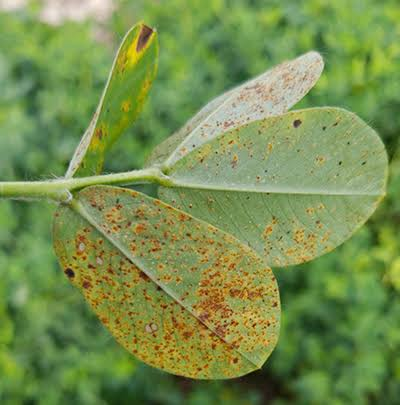

Uploaded image: images (1).jpg
Best checkpoint epoch: 21

Prediction: rust
Confidence: 96.0%

Top predictions:
  rust: 96.0%
  early_leaf_spot: 1.1%
  nutrition deficiency: 1.0%


In [26]:
from google.colab import files
from PIL import Image
from IPython.display import display
from pathlib import Path
import io
import torch

required_names = [
    "model", "class_names", "device",
    "make_full_view", "make_tile_views", "eval_transform",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(
        f"Missing notebook setup: {missing_names}. "
        "Run the model setup cell first."
    )

project_dir = Path("/content/drive/MyDrive/final_year_project/groundnut")
best_path = project_dir / "checkpoints" / "best_model.pt"
if not best_path.is_file():
    raise FileNotFoundError(f"Best checkpoint not found: {best_path}")

checkpoint = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(device)
model.eval()

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No image was uploaded.")

filename, file_bytes = next(iter(uploaded.items()))
image = Image.open(io.BytesIO(file_bytes)).convert("RGB")
display(image)

views = [make_full_view(image)] + make_tile_views(image)
views_tensor = torch.stack([eval_transform(view) for view in views]).unsqueeze(0)
views_tensor = views_tensor.to(device)

with torch.no_grad():
    logits, _ = model(views_tensor)
    probabilities = torch.softmax(logits.float(), dim=1)[0]

top_count = min(3, len(class_names))
top_probs, top_indices = torch.topk(probabilities, k=top_count)

print(f"Uploaded image: {filename}")
print(f"Best checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
print(f"\nPrediction: {class_names[top_indices[0].item()]}")
print(f"Confidence: {top_probs[0].item():.1%}")
print("\nTop predictions:")
for probability, index in zip(top_probs.tolist(), top_indices.tolist()):
    print(f"  {class_names[index]}: {probability:.1%}")